# EDA

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from pathlib import Path
from scipy.stats.contingency import association
import wfdb

In [2]:
DATA_DIR = Path(".") if Path("ptbxl_database.csv").exists() else Path("tmp")
RECORDS_DIR = DATA_DIR / "records"

ptbxl_database = pd.read_csv(DATA_DIR / "ptbxl_database.csv", low_memory=False)
scp = pd.read_csv(DATA_DIR / 'scp_statements.csv', index_col=0)

## Описание датасета

In [3]:
print("Размер таблицы:", ptbxl_database.shape)

Размер таблицы: (21799, 28)


In [4]:
display(ptbxl_database.info())
display(ptbxl_database.describe(include="all"))


<class 'pandas.DataFrame'>
RangeIndex: 21799 entries, 0 to 21798
Data columns (total 28 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   ecg_id                        21799 non-null  int64  
 1   patient_id                    21799 non-null  float64
 2   age                           21799 non-null  float64
 3   sex                           21799 non-null  int64  
 4   height                        6974 non-null   float64
 5   weight                        9421 non-null   float64
 6   nurse                         20326 non-null  float64
 7   site                          21782 non-null  float64
 8   device                        21799 non-null  str    
 9   recording_date                21799 non-null  str    
 10  report                        21799 non-null  str    
 11  scp_codes                     21799 non-null  str    
 12  heart_axis                    13331 non-null  str    
 13  infarction_s

None

,ecg_id,patient_id,age,sex,height,weight,nurse,site,device,recording_date,...,validated_by_human,baseline_drift,static_noise,burst_noise,electrodes_problems,extra_beats,pacemaker,strat_fold,filename_lr,filename_hr
count,21799.000000,21799.000000,21799.000000,21799.000000,6974.000000,9421.000000,20326.000000,21782.000000,21799,21799,...,21799,1598,3260,613,30,1949,291,21799.000000,21799,21799
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,11,21795,...,2,317,124,103,14,128,4,NaN,21799,21799
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,CS100 3,1992-02-06 11:47:42,...,True,", V6",", I-AVR,",alles,V6,1ES,"ja, pacemaker",NaN,records100/00000/00001_lr,records500/00000/00001_hr
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6140,2,...,16056,221,953,140,8,405,285,NaN,1,1
mean,10926.658379,11250.156521,62.769301,0.479150,166.702323,70.995223,2.291745,1.544945,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.503005,NaN,NaN
std,6302.393366,6235.026404,32.308813,0.499577,10.867321,15.878803,3.254033,4.172883,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.874948,NaN,NaN
min,1.000000,302.000000,2.000000,0.000000,6.000000,5.000000,0.000000,0.000000,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,NaN,NaN
25%,5469.500000,5974.500000,50.000000,0.000000,160.000000,60.000000,0.000000,0.000000,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.000000,NaN,NaN
50%,10926.000000,11419.000000,62.000000,0.000000,166.000000,70.000000,1.000000,1.000000,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.000000,NaN,NaN
75%,16386.500000,16607.500000,72.000000,1.000000,174.000000,80.000000,3.000000,2.000000,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.000000,NaN,NaN


In [5]:
display(ptbxl_database.head())
print('Уникальных записей ЭКГ:', ptbxl_database['ecg_id'].nunique())
print('Уникальных пациентов:', ptbxl_database['patient_id'].nunique())
print('Уникален ли ecg_id:', ptbxl_database['ecg_id'].is_unique)

,ecg_id,patient_id,age,sex,height,weight,nurse,site,device,recording_date,...,validated_by_human,baseline_drift,static_noise,burst_noise,electrodes_problems,extra_beats,pacemaker,strat_fold,filename_lr,filename_hr
0,1,15709.0,56.0,1,NaN,63.0,2.0,0.0,CS-12 E,1984-11-09 09:17:34,...,True,NaN,", I-V1,",NaN,NaN,NaN,NaN,3,records100/00000/00001_lr,records500/00000/00001_hr
1,2,13243.0,19.0,0,NaN,70.0,2.0,0.0,CS-12 E,1984-11-14 12:55:37,...,True,NaN,NaN,NaN,NaN,NaN,NaN,2,records100/00000/00002_lr,records500/00000/00002_hr
2,3,20372.0,37.0,1,NaN,69.0,2.0,0.0,CS-12 E,1984-11-15 12:49:10,...,True,NaN,NaN,NaN,NaN,NaN,NaN,5,records100/00000/00003_lr,records500/00000/00003_hr
3,4,17014.0,24.0,0,NaN,82.0,2.0,0.0,CS-12 E,1984-11-15 13:44:57,...,True,", II,III,AVF",NaN,NaN,NaN,NaN,NaN,3,records100/00000/00004_lr,records500/00000/00004_hr
4,5,17448.0,19.0,1,NaN,70.0,2.0,0.0,CS-12 E,1984-11-17 10:43:15,...,True,", III,AVR,AVF",NaN,NaN,NaN,NaN,NaN,4,records100/00000/00005_lr,records500/00000/00005_hr


Уникальных записей ЭКГ: 21799
Уникальных пациентов: 18869
Уникален ли ecg_id: True


## Анализ пропусков и ошибок в данных

In [6]:
rows = []

for col in ptbxl_database.columns:
    values = ptbxl_database[col].dropna()       # Значения без пропусков

    rows.append({
        'Столбец': col,
        'Непустых': values.size,
        'Пропусков': ptbxl_database[col].isna().sum(),
    })

info = pd.DataFrame(rows)

with pd.option_context(
    'display.max_rows', None,
    'display.max_colwidth', None
):
    display(info)

,Столбец,Непустых,Пропусков
0,ecg_id,21799,0
1,patient_id,21799,0
2,age,21799,0
3,sex,21799,0
4,height,6974,14825
5,weight,9421,12378
6,nurse,20326,1473
7,site,21782,17
8,device,21799,0
9,recording_date,21799,0


In [65]:
h_bad = ptbxl_database["height"] < 100
w_bad = ptbxl_database["weight"] < 20
a_ok  = ptbxl_database["age"] >= 18

invalid_physio = ptbxl_database[((h_bad | w_bad) & a_ok)][["ecg_id", "age", "height", "weight"]]

display(invalid_physio.shape)
display(invalid_physio)

(12, 4)

,ecg_id,age,height,weight
4675,4695,82.0,175.0,17.0
6038,6059,63.0,173.0,5.0
6245,6266,60.0,66.0,NaN
6409,6430,46.0,67.0,NaN
6460,6481,76.0,80.0,NaN
7921,7945,77.0,165.0,5.0
9293,9317,64.0,6.0,NaN
9360,9384,79.0,6.0,NaN
15170,15207,86.0,6.0,NaN
15314,15351,84.0,90.0,NaN


При проверке числовых признаков обнаружены потенциально ошибочные значения роста и веса, например, у некоторых взрослых пациентов указан рост 6 см или вес 5 кг, что свидетельствует о вероятных ошибках ввода данных.

Для пациентов старше 89 лет, данные обезличены путем установки возраста 300.

In [54]:
ptbxl_database[
    ptbxl_database["age"] < 0 |
    ((ptbxl_database["age"] > 89) &
    (ptbxl_database["age"] != 300))
][["ecg_id", "age", "height", "weight"]]

,ecg_id,age,height,weight


Записи с некорректным возрастом отсутствуют

Распределение записей по категориальным меткам

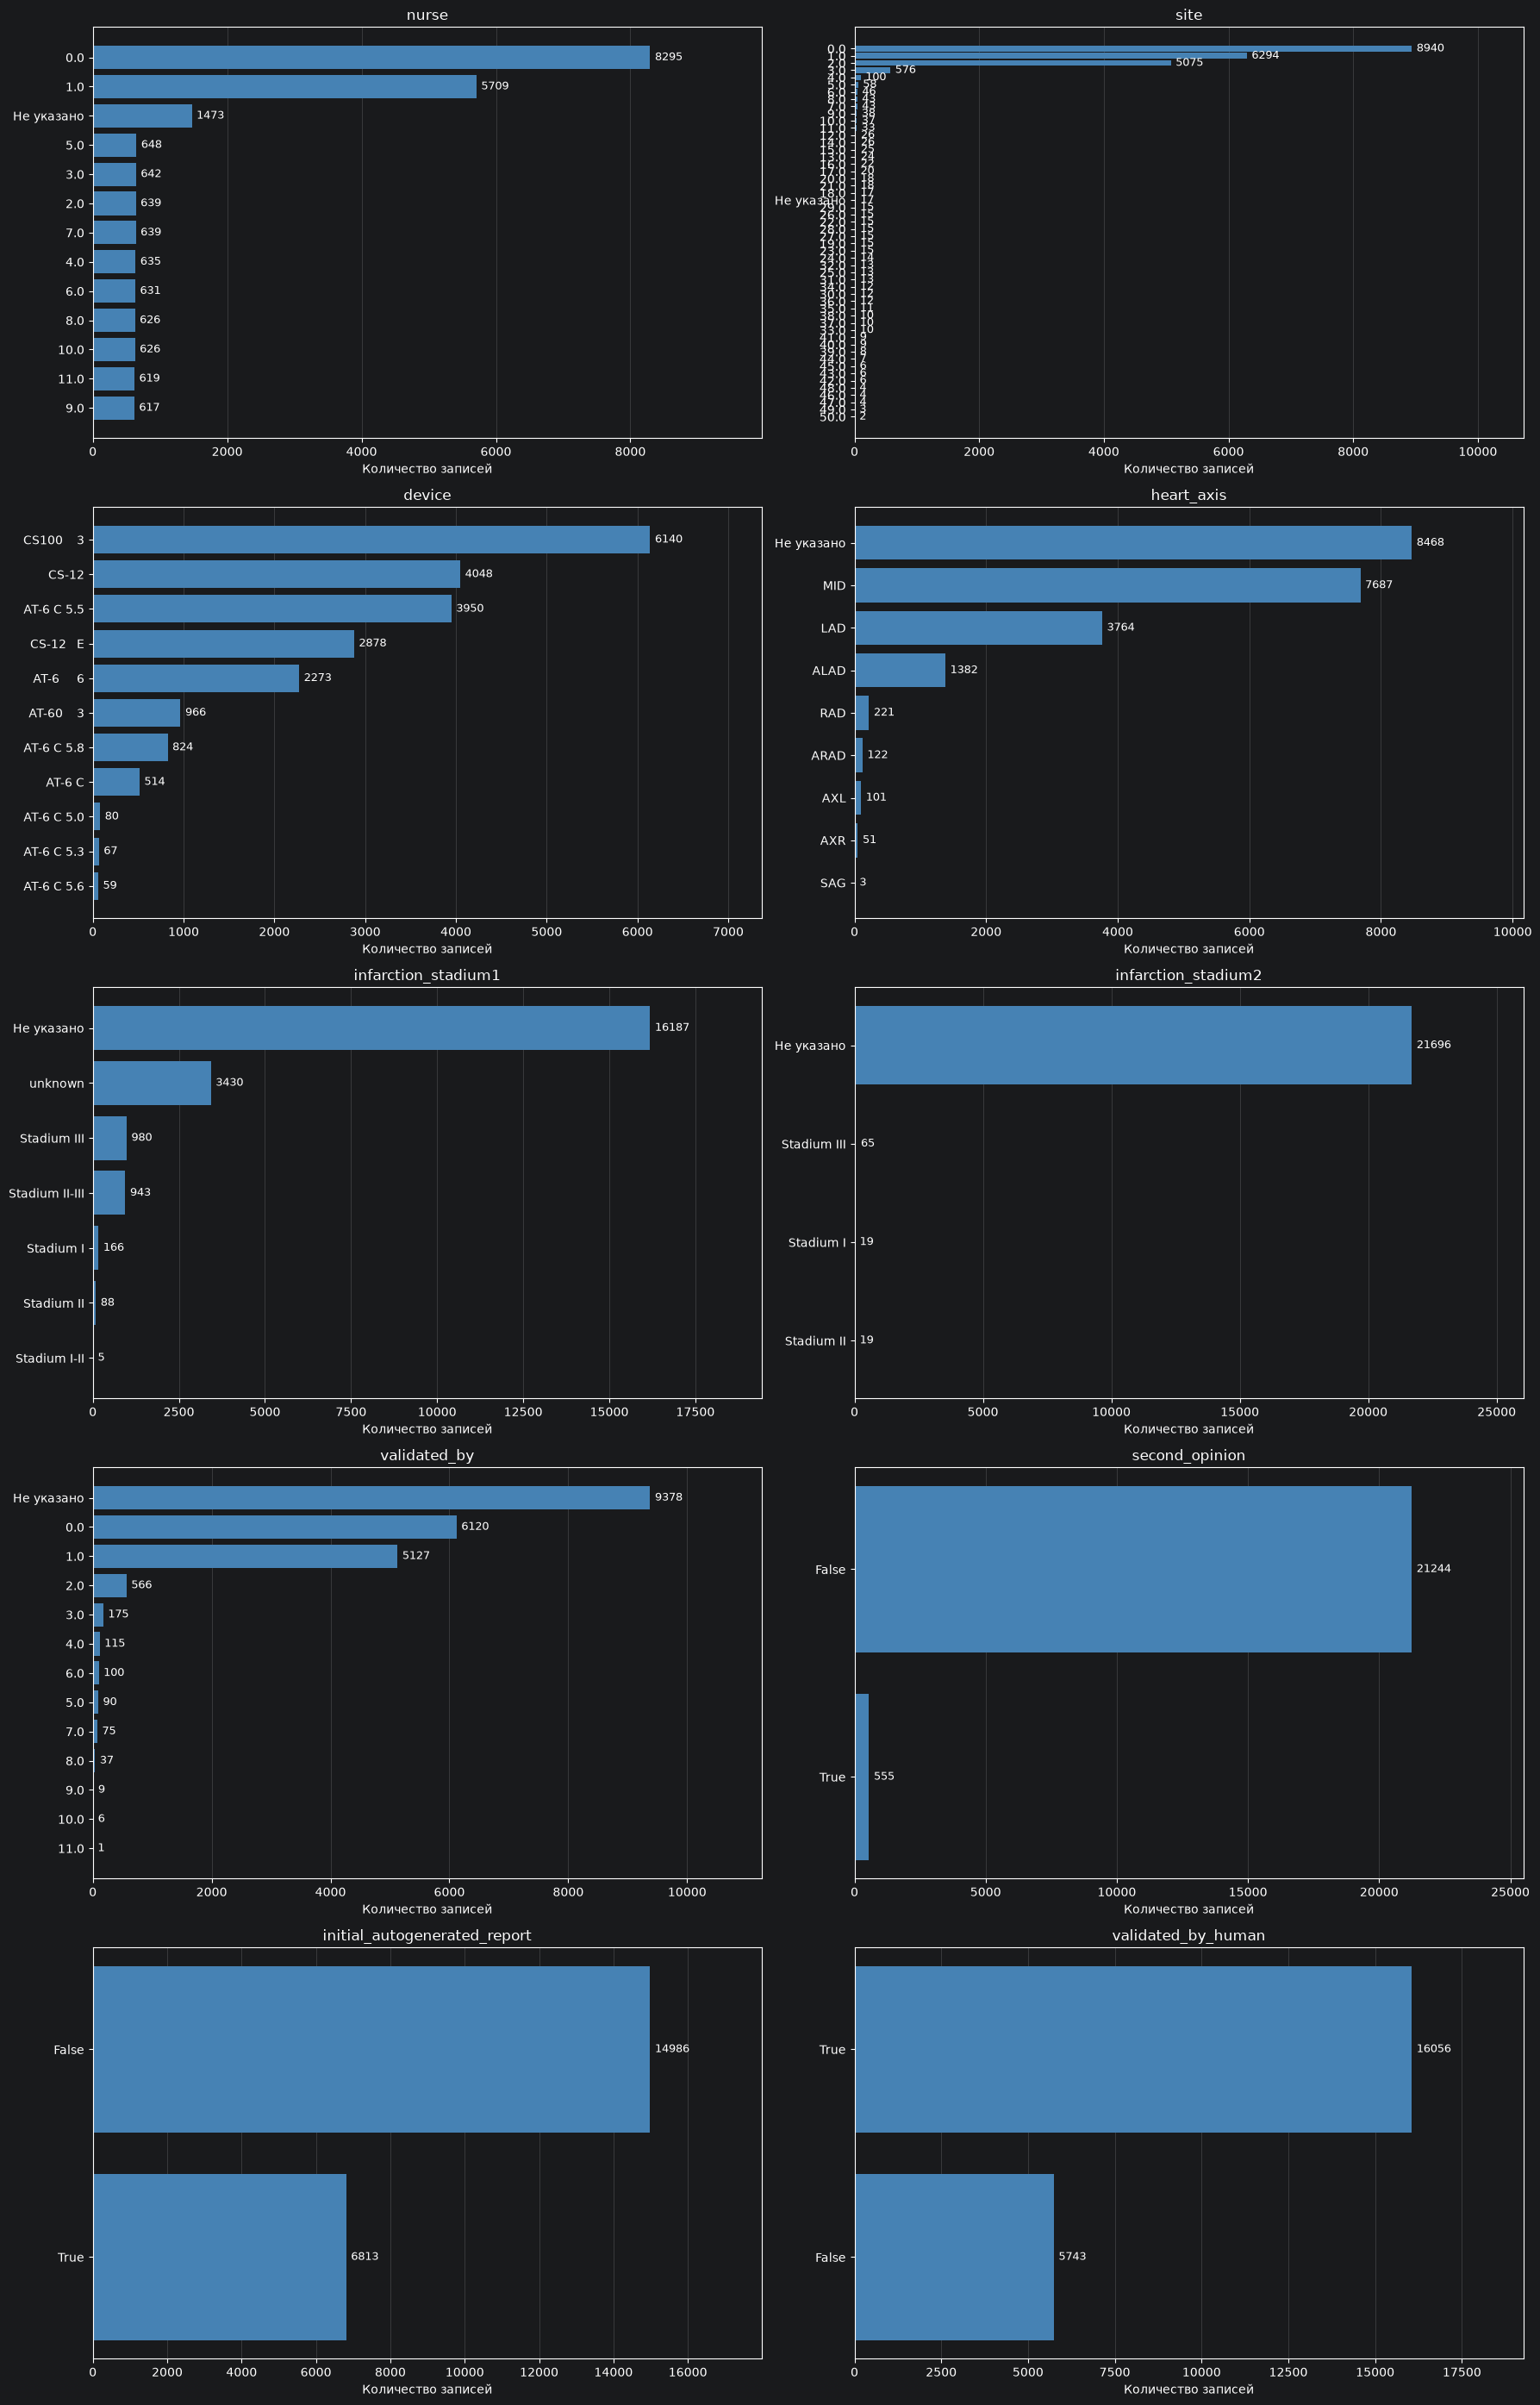

,count,unique,top,freq,missing
nurse,20326.0,12.0,0.0,8295.0,1473
site,21782.0,51.0,0.0,8940.0,17
device,21799,11,CS100 3,6140,0
heart_axis,13331,8,MID,7687,8468
infarction_stadium1,5612,6,unknown,3430,16187
infarction_stadium2,103,3,Stadium III,65,21696
validated_by,12421.0,12.0,0.0,6120.0,9378
second_opinion,21799,2,False,21244,0
initial_autogenerated_report,21799,2,False,14986,0
validated_by_human,21799,2,True,16056,0


In [8]:
columns = [
    'nurse',
    'site',
    'device',
    'heart_axis',
    'infarction_stadium1',
    'infarction_stadium2',
    'validated_by',
    'second_opinion',
    'initial_autogenerated_report',
    'validated_by_human'
]

# Папка для сохранения графиков
output_dir = Path.cwd() / 'metadata_plots'
output_dir.mkdir(exist_ok=True)

# Рассматриваем столбцы как категориальные
# Исходная таблица df не изменяется
categories = ptbxl_database[columns].astype('category')

fig, axes = plt.subplots(5, 2, figsize=(18, 28))

for ax, col in zip(axes.flat, columns):
    # Показываем пропуски отдельной категорией
    values = categories[col].astype('string').fillna('Не указано')
    counts = values.value_counts()

    bars = ax.barh(
        counts.index,
        counts.values,
        color='steelblue'
    )

    ax.bar_label(bars, padding=4, fontsize=9)
    ax.invert_yaxis()

    ax.set(
        title=col,
        xlabel='Количество записей',
        ylabel=''
    )

    ax.margins(x=0.2)
    ax.grid(axis='x', alpha=0.3)
    ax.set_axisbelow(True)

plt.tight_layout()

# Сохраняем общий рисунок
fig.savefig(
    output_dir / 'metadata_distributions.png',
    dpi=300,
    bbox_inches='tight',
    facecolor='white'
)

# Определяем границы графиков вместе с подписями
fig.canvas.draw()
renderer = fig.canvas.get_renderer()

# Сохраняем каждый график отдельно
for ax, col in zip(axes.flat, columns):
    area = ax.get_tightbbox(renderer)
    area = area.transformed(fig.dpi_scale_trans.inverted())
    area = area.padded(0.15)


plt.show()

# Основные статистики по категориям
stats = (
    categories
    .describe(include='all')
    .loc[['count', 'unique', 'top', 'freq']]
    .T
)

stats['missing'] = categories.isna().sum()

display(stats)

## Формирование целевой переменной

In [9]:
import ast
ptbxl_database["scp_codes"] = ptbxl_database["scp_codes"].apply(ast.literal_eval)
ptbxl_database["scp_codes"].head()

0    {'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}
1                {'NORM': 80.0, 'SBRAD': 0.0}
2                  {'NORM': 100.0, 'SR': 0.0}
3                  {'NORM': 100.0, 'SR': 0.0}
4                  {'NORM': 100.0, 'SR': 0.0}
Name: scp_codes, dtype: object

In [10]:
diagnostic_scp = scp[scp["diagnostic"] == 1]
code_to_class = diagnostic_scp["diagnostic_class"].dropna().to_dict()

def get_classes(codes):
    classes = []

    for code in codes:
        if code in code_to_class:
            cls = code_to_class[code]

            if cls not in classes:
                classes.append(cls)

    return classes

ptbxl_database["diagnostic_classes"] = ptbxl_database["scp_codes"].apply(get_classes)

ptbxl_database[["scp_codes", "diagnostic_classes"]].head(10)

,scp_codes,diagnostic_classes
0,"{'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}",[NORM]
1,"{'NORM': 80.0, 'SBRAD': 0.0}",[NORM]
2,"{'NORM': 100.0, 'SR': 0.0}",[NORM]
3,"{'NORM': 100.0, 'SR': 0.0}",[NORM]
4,"{'NORM': 100.0, 'SR': 0.0}",[NORM]
5,"{'NORM': 100.0, 'SR': 0.0}",[NORM]
6,"{'NORM': 100.0, 'SR': 0.0}",[NORM]
7,"{'IMI': 35.0, 'ABQRS': 0.0, 'SR': 0.0}",[MI]
8,"{'NORM': 100.0, 'SR': 0.0}",[NORM]
9,"{'NORM': 100.0, 'SR': 0.0}",[NORM]


Для обучения базовых моделей в качестве целевой переменной планируется использовать вектор, содержащий бинарные признаки наличия\отсутствия меток суперклассов (все диагностические метки распределены в 5 суперклассов. Метки формы и ритма пока опускаются).

### Описание суперклассов
#### NORM — норма (1 метка)
#### MI — инфаркт миокарда (14 меток)
#### STTC — изменения ST-T / ишемия (13 меток)
#### CD — нарушения проводимости (11 меток)
#### HYP — гипертрофия и перегрузка (5 меток)

### Анализ распределения целевой переменной

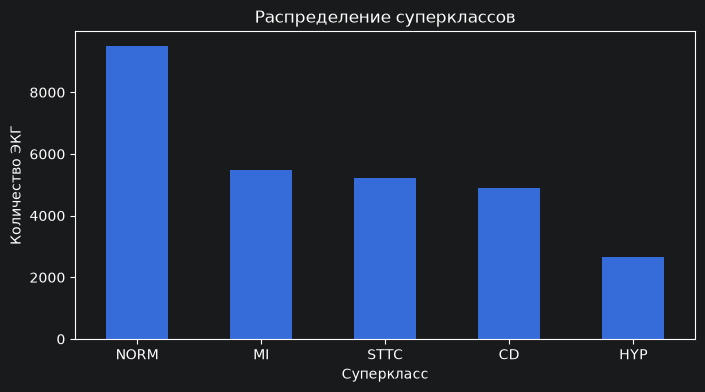

NORM    9514
MI      5469
STTC    5235
CD      4898
HYP     2649
dtype: int64

In [11]:
classes = ["NORM", "MI", "STTC", "CD", "HYP"]

class_counts = {}

for cls in classes:
    class_counts[cls] = ptbxl_database["diagnostic_classes"].apply(
        lambda x: cls in x
    ).sum()

class_counts = pd.Series(class_counts)

class_counts.plot(kind="bar", figsize=(8, 4))

plt.title("Распределение суперклассов")
plt.xlabel("Суперкласс")
plt.ylabel("Количество ЭКГ")
plt.xticks(rotation=0)
plt.show()

class_counts

Распределение диагностических суперклассов неравномерно. Наиболее представлен класс NORM (9528 записей), наименее HYP (2655 записей). При дальнейшем обучении модели потребуется учитывать дисбаланс классов

Распределение числа суперклассов на запись

diagnostic_classes
0      411
1    16244
2     4068
3      919
4      157
Name: count, dtype: int64


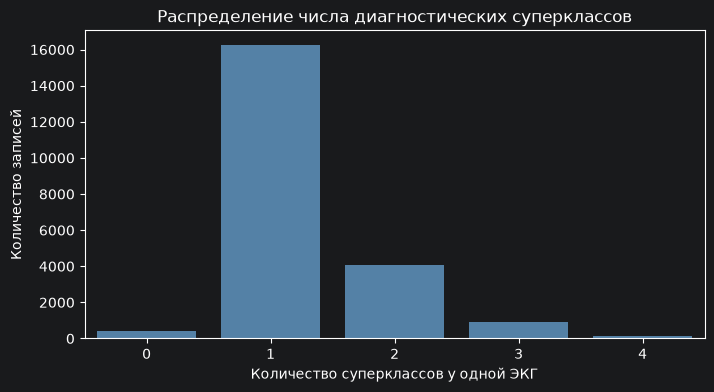

In [12]:
class_num = ptbxl_database["diagnostic_classes"].apply(len)

print(class_num.value_counts().sort_index())

plt.figure(figsize=(8, 4))
sns.countplot(x=class_num, color="steelblue")

plt.xlabel("Количество суперклассов у одной ЭКГ")
plt.ylabel("Количество записей")
plt.title("Распределение числа диагностических суперклассов")
plt.show()

Совместная встречаемость суперклассов

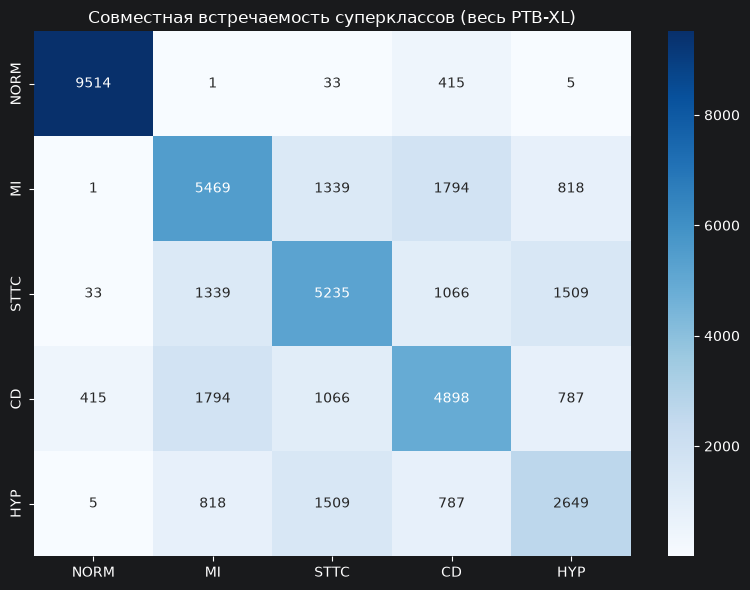

In [13]:
classes = ["NORM", "MI", "STTC", "CD", "HYP"]

labels = pd.DataFrame({
    cls: ptbxl_database["diagnostic_classes"].apply(lambda x: int(cls in x))
    for cls in classes
})

cooccurrence = labels.T @ labels

plt.figure(figsize=(8, 6))
sns.heatmap(cooccurrence, annot=True, fmt="d", cmap="Blues")

plt.title("Совместная встречаемость суперклассов (весь PTB-XL)")
plt.tight_layout()
plt.show()

Во всей выборке встречается около 400 записей без диагностических меток, следовательно, они не имеют суперклассов. Для первоначального обучения модели планируется исключить эти записи, поскольку они не имеют целевых меток в рамках выбранной задачи.

In [14]:
ptbxl_database = ptbxl_database[
    ptbxl_database["diagnostic_classes"].apply(lambda x: len(x) > 0)
]

## Анализ файлов ЭКГ

Для каждой записи об ЭКГ в датасете присутствуют 2 файла с сырыми сигналами ЭКГ: с частотой дискретизации 100 Гц (low resolution) - {record_name}_lr, и 500 Гц (high resolution) - {record_name}_hr. Для примера выбрана запись ЭКГ без патологий и с нормальным ритмом

In [15]:
record_lr = wfdb.rdrecord(RECORDS_DIR / "00003_lr")
record_hr = wfdb.rdrecord(RECORDS_DIR / "00003_hr")

Длительность всех записей - 10 сек, снимаются сигналы по 12 отведениям.

In [16]:
print(f"Low res shape: {record_lr.p_signal.shape}")
print(f"High res shape: {record_hr.p_signal.shape}")

Low res shape: (1000, 12)
High res shape: (5000, 12)


Пример графика ЭКГ и сырых данных

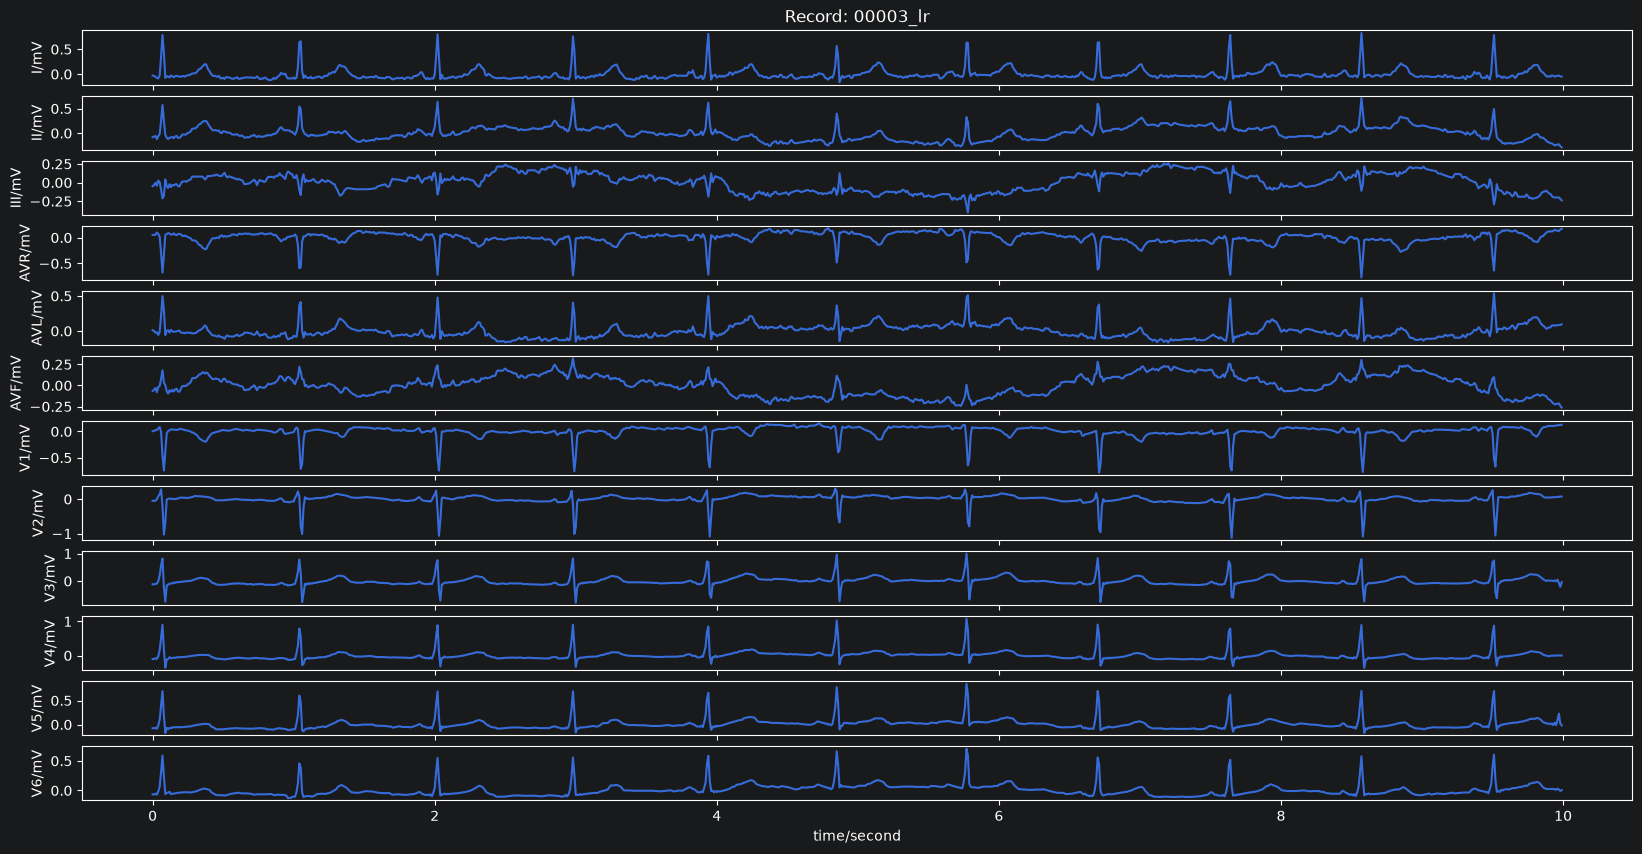

In [17]:
wfdb.plot_wfdb(record_lr, figsize=(20, 10))

In [18]:
print(record_lr.p_signal)

[[-0.029 -0.079 -0.049 ... -0.103 -0.076 -0.066]
 [-0.035 -0.07  -0.035 ... -0.104 -0.079 -0.068]
 [-0.054 -0.057 -0.003 ... -0.078 -0.066 -0.054]
 ...
 [-0.029 -0.226 -0.198 ...  0.001  0.229  0.018]
 [-0.048 -0.266 -0.218 ... -0.001  0.021 -0.008]
 [-0.049 -0.288 -0.239 ...  0.001 -0.018  0.006]]


Сравнение lr и hr записи по одному из отведений на 2-х секундном отрезке

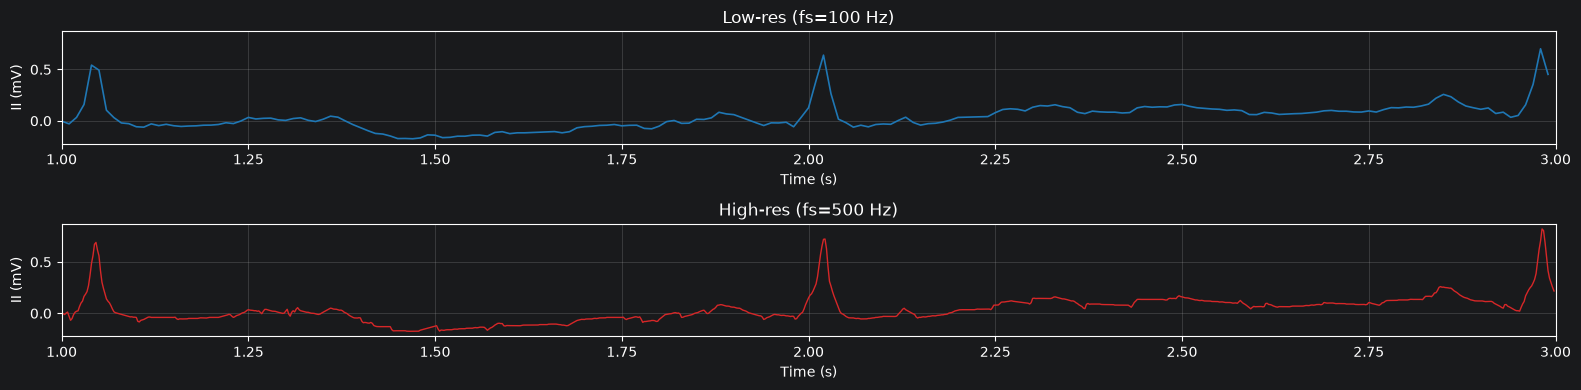

In [19]:
lead_idx = 1
t_start, t_end = 1.0, 3.0

def crop(rec, lead, t0, t1):
    i0 = int(t0 * rec.fs)
    i1 = int(t1 * rec.fs)
    return rec.p_signal[i0:i1, lead], rec.fs

sig_low,  fs_low  = crop(record_lr,  lead_idx, t_start, t_end)
sig_high, fs_high = crop(record_hr, lead_idx, t_start, t_end)

t_low  = t_start + np.arange(len(sig_low))  / fs_low
t_high = t_start + np.arange(len(sig_high)) / fs_high

fig, axes = plt.subplots(2, 1, figsize=(16, 4), sharey=True)

axes[0].plot(t_low, sig_low, color='tab:blue', linewidth=1.2)
axes[0].set_title(f'Low-res (fs={fs_low} Hz)')
axes[0].set_xlabel('Time (s)')
axes[0].set_ylabel(f'{record_lr.sig_name[lead_idx]} (mV)')
axes[0].set_xlim(t_start, t_end)
axes[0].grid(True, alpha=0.3)

axes[1].plot(t_high, sig_high, color='tab:red', linewidth=1.0)
axes[1].set_title(f'High-res (fs={fs_high} Hz)')
axes[1].set_xlabel('Time (s)')
axes[1].set_ylabel(f'{record_hr.sig_name[lead_idx]} (mV)')
axes[1].set_xlim(t_start, t_end)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Анализ сырых данных ЭКГ на примере lr записи

In [20]:
signal = record_lr.p_signal
channel_names = record_lr.sig_name
units = record_lr.units

stats = []
for i, name in enumerate(channel_names):
    ch = signal[:, i]
    ch = ch[~np.isnan(ch)]
    mn  = np.min(ch)
    mx  = np.max(ch)
    amp = mx - mn
    stats.append({
        'channel': name,
        'min': mn,
        'max': mx,
        'amplitude': amp,
        'unit': units[i],
    })

print(f"{'Channel':<8} {'Min':>10} {'Max':>10} {'Amplitude':>12} {'Unit':>6}")
for s in stats:
    print(f"{s['channel']:<8} {s['min']:>10.4f} {s['max']:>10.4f} "
          f"{s['amplitude']:>12.4f} {s['unit']:>6}")

Channel         Min        Max    Amplitude   Unit
I           -0.1640     0.8270       0.9910     mV
II          -0.2880     0.7150       1.0030     mV
III         -0.4000     0.2610       0.6610     mV
AVR         -0.7710     0.1830       0.9540     mV
AVL         -0.1650     0.5390       0.7040     mV
AVF         -0.2630     0.3220       0.5850     mV
V1          -0.7840     0.1540       0.9380     mV
V2          -1.1210     0.3090       1.4300     mV
V3          -0.7910     1.0000       1.7910     mV
V4          -0.3630     1.0820       1.4450     mV
V5          -0.1750     0.8510       1.0260     mV
V6          -0.1280     0.7050       0.8330     mV


### Примеры записей

Патология (MI) и аномальная форма

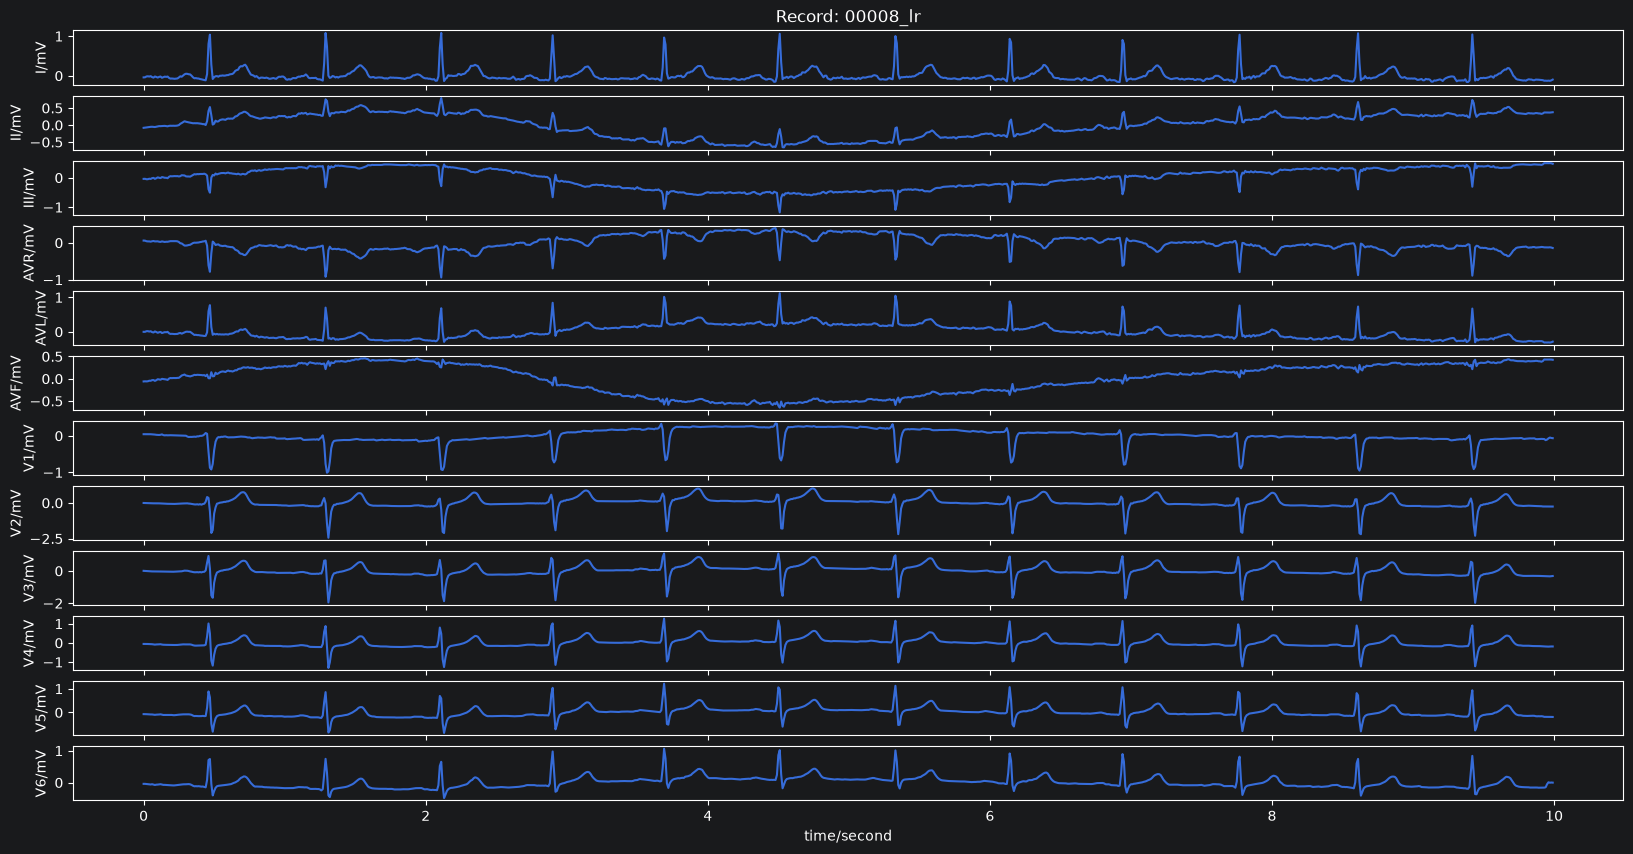

In [21]:
record = wfdb.rdrecord(RECORDS_DIR / "00008_lr")
wfdb.plot_wfdb(record, figsize=(20, 10))
del record

Патология (CD), проблемы с электродом на V4

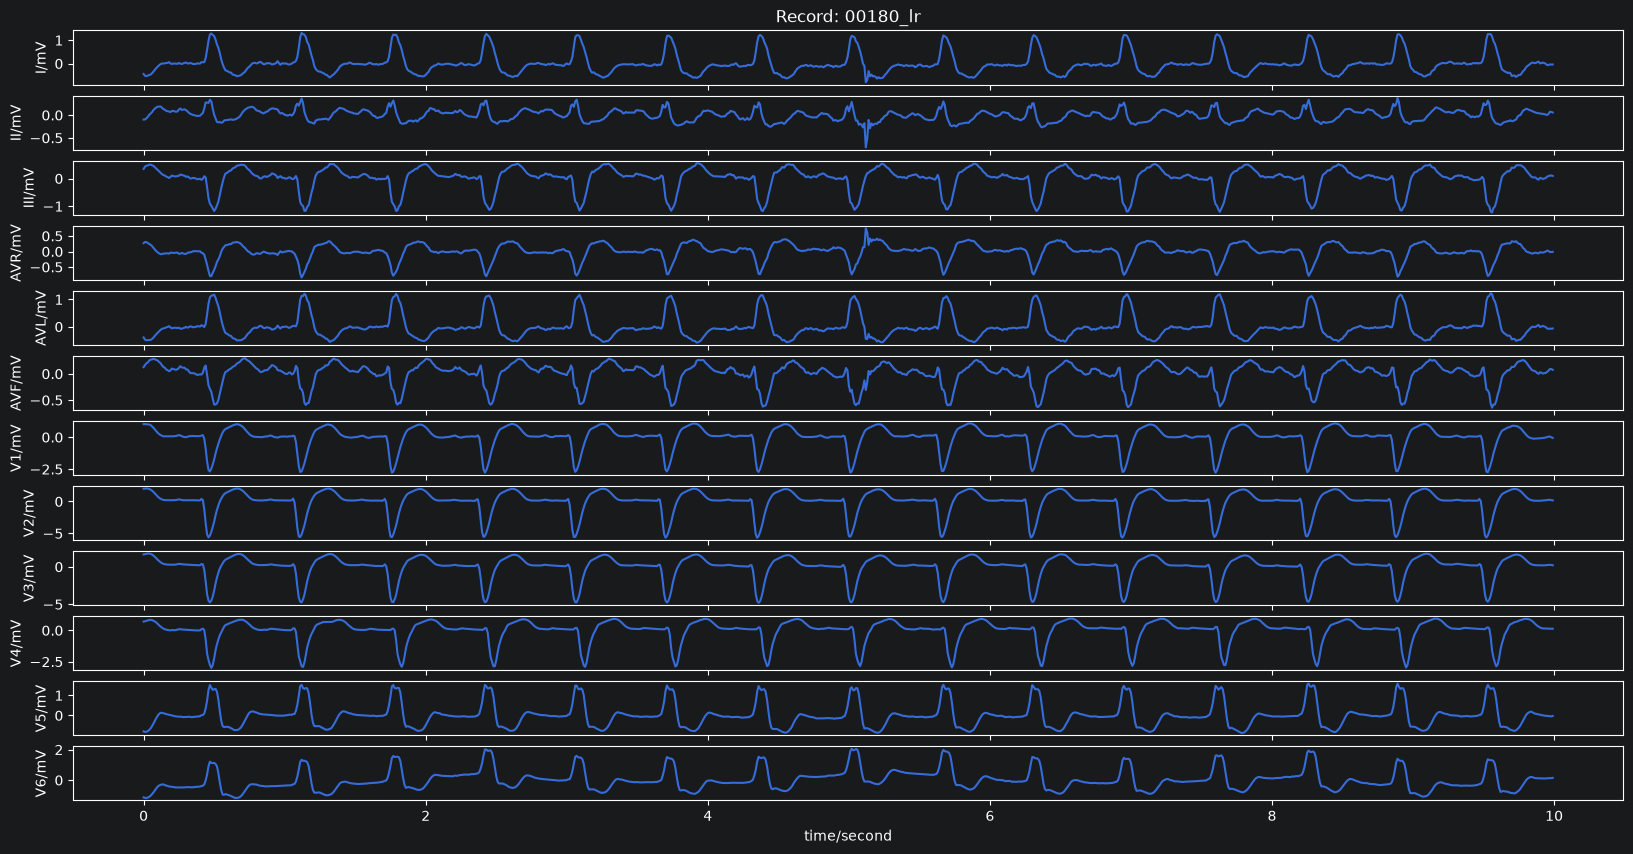

In [22]:
record = wfdb.rdrecord(RECORDS_DIR / "00180_lr")
wfdb.plot_wfdb(record, figsize=(20, 10))
del record

Без патологий, дрифт на V3, шум на I-V2

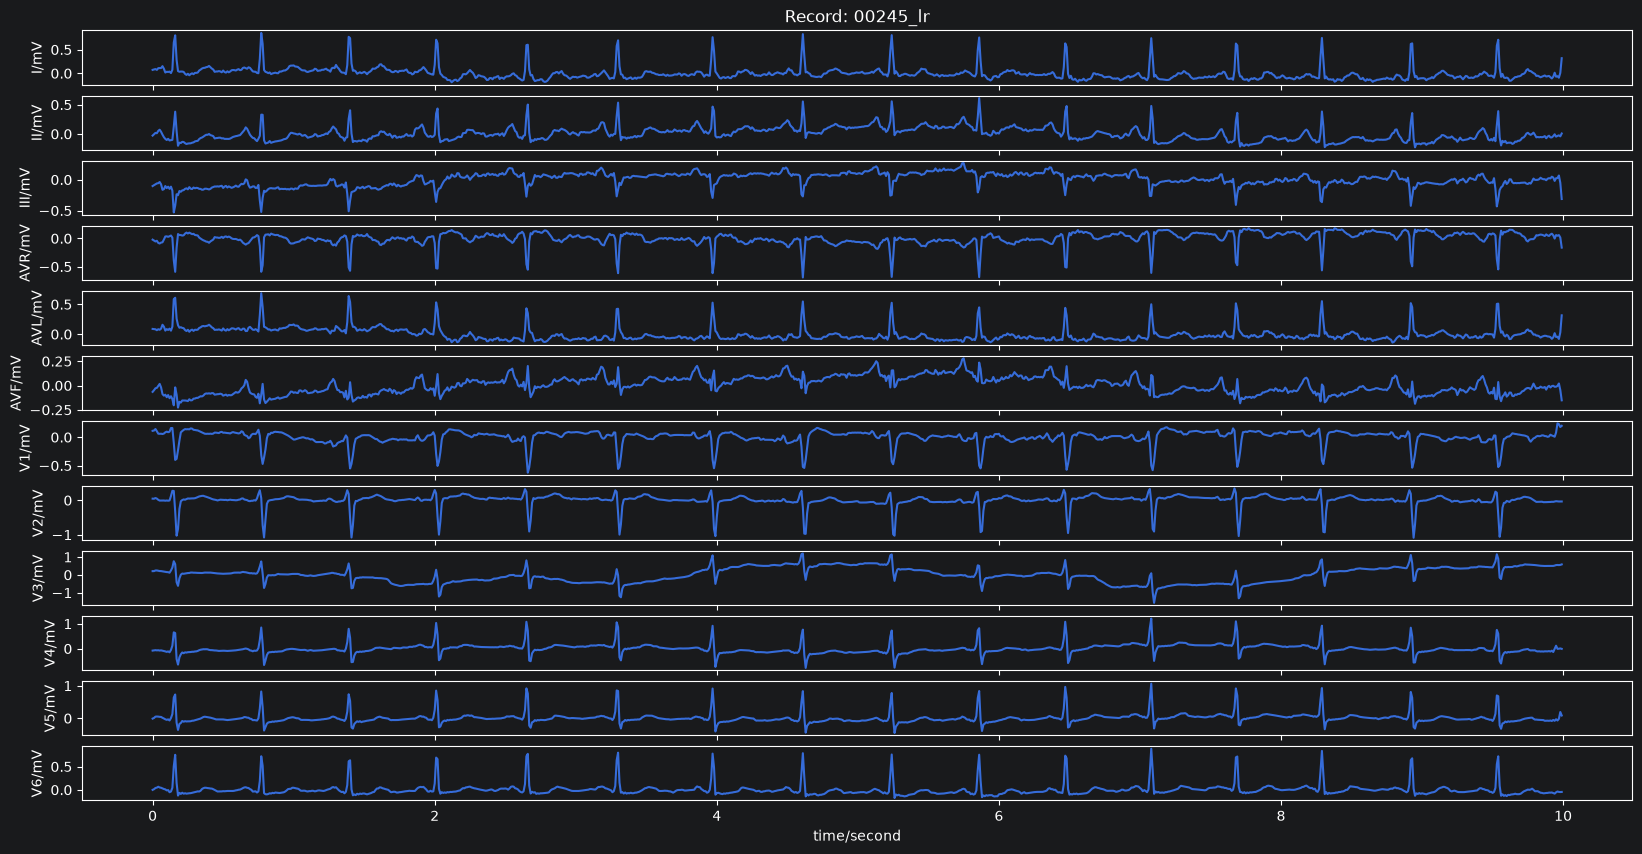

In [23]:
record = wfdb.rdrecord(RECORDS_DIR / "00245_lr")
wfdb.plot_wfdb(record, figsize=(20, 10))
del record

## Отделение обучающей выборки

In [24]:
train_data = ptbxl_database.loc[ptbxl_database['strat_fold'].between(1, 8)].copy()
train_data = train_data.reset_index(drop=True)
val_data   = ptbxl_database.loc[ptbxl_database['strat_fold'] == 9].copy()
test_data  = ptbxl_database.loc[ptbxl_database['strat_fold'] == 10].copy()

print(f"Train: {len(train_data)} записей")
print(f"Val:   {len(val_data)} записей")
print(f"Test:  {len(test_data)} записей")
print(f"Всего: {len(train_data) + len(val_data) + len(test_data)} из {len(ptbxl_database)}")

Train: 17084 записей
Val:   2146 записей
Test:  2158 записей
Всего: 21388 из 21388


Проверка пересечений пациентов

In [25]:
train_pat = set(train_data['patient_id'])
val_pat   = set(val_data['patient_id'])
test_pat  = set(test_data['patient_id'])

print(f"Пациентов — train: {len(train_pat)}, val: {len(val_pat)}, test: {len(test_pat)}")
print(f"Пересечение train∩val:  {len(train_pat & val_pat)}")
print(f"Пересечение train∩test: {len(train_pat & test_pat)}")
print(f"Пересечение val∩test:   {len(val_pat & test_pat)}")
print(f"Всего уникальных пациентов: {len(train_pat | val_pat | test_pat)}")

Пациентов — train: 14823, val: 1917, test: 1877
Пересечение train∩val:  0
Пересечение train∩test: 0
Пересечение val∩test:   0
Всего уникальных пациентов: 18617


Распределение числа записей на пациента

In [26]:
records_per_patient = ptbxl_database.groupby('patient_id').size()
print(records_per_patient.describe())
print("\nРаспределение количества записей на пациента:")
print(records_per_patient.value_counts().sort_index())

count    18617.000000
mean         1.148842
std          0.503242
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max         10.000000
dtype: float64

Распределение количества записей на пациента:
1     16585
2      1549
3       331
4        92
5        36
6        14
7         4
8         3
9         2
10        1
Name: count, dtype: int64


## Анализ пропусков в обучающей выборке

In [37]:
missing_percent = (train_data.isna().mean() * 100).round(1)

missing_percent.sort_values(ascending=False)

pacemaker                       99.9
electrodes_problems             99.9
infarction_stadium2             99.5
burst_noise                     97.1
baseline_drift                  93.4
extra_beats                     91.2
static_noise                    84.9
infarction_stadium1             73.7
height                          67.7
weight                          57.9
validated_by                    46.6
heart_axis                      37.1
nurse                            6.0
age                              1.2
site                             0.1
recording_date                   0.0
report                           0.0
patient_id                       0.0
ecg_id                           0.0
sex                              0.0
device                           0.0
scp_codes                        0.0
initial_autogenerated_report     0.0
second_opinion                   0.0
validated_by_human               0.0
strat_fold                       0.0
filename_lr                      0.0
f

В обучающей выборке обнаружено большое количество пропусков в данных о росте (68,1%), весе (58,5%) и ИМТ (69,1%). При этом возраст практически полностью заполнен (0,4% пропусков), а пол указан для всех записей

In [40]:
classes = ["NORM", "MI", "STTC", "CD", "HYP"]

for cls in classes:
    group = train_data[train_data   ["diagnostic_classes"].apply(lambda x: cls in x)]

    print(
        cls,
        "Рост:", round(group["height"].isna().mean() * 100, 1), "%",
        "Вес:", round(group["weight"].isna().mean() * 100, 1), "%"
    )

NORM Рост: 65.6 % Вес: 46.7 %
MI Рост: 74.5 % Вес: 73.1 %
STTC Рост: 64.2 % Вес: 62.8 %
CD Рост: 68.2 % Вес: 64.0 %
HYP Рост: 60.9 % Вес: 60.3 %


Количество пропусков роста и веса действительно различается между диагностическими суперклассами. Особенно заметны различия в заполненности веса: у пациентов класса NORM он отсутствует в 46,7% записей, а у MI в 73,1%

Пропуски по возрастным группам (в процентах тоже)

In [42]:
age_groups = pd.cut(
    train_data["age"],
    bins=[0, 18, 40, 60, 90, float("inf")],
    labels=["До 18", "18–39", "40–59", "60–89", "90+"],
    right=False
)

train_data.groupby(age_groups, observed=True)[["height", "weight"]].apply(
    lambda x: (x.isna().mean() * 100).round(1)
)

,height,weight
age,,
До 18,69.4,34.2
18–39,79.5,36.0
40–59,75.6,63.4
60–89,60.7,60.2


Больше всего пропусков роста наблюдается в группе 18–39 лет (79,5%), а веса в группе 40–59 лет (63,4%). Это показывает, что заполненность метаданных может зависеть от возраста пациента

Анализ пропусков роста и веса по местам регистрации ЭКГ



In [43]:
train_data.groupby("site")[["height", "weight"]].apply(
    lambda x: (x.isna().mean() * 100).round(1)
)

,height,weight
site,,
0.0,99.8,76.2
1.0,5.5,7.8
2.0,98.3,98.5
3.0,89.5,89.5
4.0,27.4,28.8
5.0,20.0,22.0
6.0,0.0,0.0
7.0,3.3,3.3
8.0,0.0,0.0


Сколько ЭКГ приходится на каждое место

In [44]:
train_data["site"].value_counts().head(10)

site
0.0     7691
1.0     5038
2.0     3318
3.0      332
4.0       73
5.0       50
6.0       37
8.0       33
7.0       30
11.0      29
Name: count, dtype: int64

Анализ обучающей выборки показал, что 93,9% записей ЭКГ получены из трёх мест регистрации. При этом заполненность роста и веса сильно различается между ними, например, в site 0 отсутствует 99,8% значений роста, а в site 1 только 5,5%

Сколько записей приходится на каждое устройство

In [46]:
train_data["device"].value_counts()

device
CS100    3    5766
AT-6 C 5.5    3147
CS-12         2679
CS-12   E     1980
AT-6     6    1798
AT-6 C 5.8     671
AT-60    3     606
AT-6 C         289
AT-6 C 5.0      51
AT-6 C 5.3      49
AT-6 C 5.6      48
Name: count, dtype: int64

In [47]:
pd.crosstab(
    train_data["device"],
    train_data["initial_autogenerated_report"],
    normalize="index"
).round(2)

initial_autogenerated_report,False,True
device,,
AT-6 6,1.00,0.00
AT-6 C,1.00,0.00
AT-6 C 5.0,1.00,0.00
AT-6 C 5.3,1.00,0.00
AT-6 C 5.5,1.00,0.00
AT-6 C 5.6,1.00,0.00
AT-6 C 5.8,1.00,0.00
AT-60 3,0.05,0.95
CS-12,1.00,0.00


Анализ обучающей выборки показал сильную связь между устройством регистрации ЭКГ и автоматическим формированием первоначального заключения. Для CS100 3 автоматически сформированы 97% заключений, для AT-60 3 95%, тогда как для остальных устройств таких записей нет

## Анализ корреляции метаданных с целевой переменной

In [27]:
# Обучающая часть для исследовательского анализа
data = train_data

# Числовые признаки
num_cols = ['age', 'height', 'weight']

# Категориальные признаки
cat_cols = [
    'sex',
    'nurse',
    'site',
    'device',
    'heart_axis',
    'infarction_stadium1',
    'infarction_stadium2',
    'validated_by',
    'second_opinion',
    'initial_autogenerated_report',
    'validated_by_human'
]

# Возраст > 89 не используем как точное числовое значение
data['age'] = data['age'].where(data['age'].between(0, 89))

# Читаем словари с метками
codes = data['scp_codes'].apply(
    lambda value: ast.literal_eval(value)
    if isinstance(value, str) else value
)

diagnostic_codes = set(scp.index[scp['diagnostic'] == 1])

# Отсортированный набор диагностических меток каждой записи
labels = codes.apply(
    lambda record: tuple(sorted(
        code for code in record
        if code in diagnostic_codes
    ))
)

# Записи без диагностических меток исключаем из анализа таргета
has_diagnosis = labels.apply(len) > 0

print('Записей для анализа:', len(data))
print('Без диагностических меток:', (~has_diagnosis).sum())

# Матрица: строки — записи, столбцы — диагнозы, значения — 0 или 1
target = pd.DataFrame({
    code: labels.apply(lambda record: int(code in record))
    for code in sorted(diagnostic_codes)
})

# Точное сочетание диагностических меток
label_set = labels.apply(', '.join).rename('Диагноз')

Записей для анализа: 17084
Без диагностических меток: 0


In [28]:
rows = []

for feature in num_cols:
    for diagnosis in target.columns:
        x = data.loc[has_diagnosis, feature]
        y = target.loc[has_diagnosis, diagnosis]

        valid = x.notna()
        x = x[valid]
        y = y[valid]

        r = np.nan

        if len(x) >= 3 and x.nunique() > 1 and y.nunique() == 2:
            r = x.corr(y, method='pearson')

        rows.append({
            'Признак': feature,
            'Диагноз': diagnosis,
            'Корреляция': r,
            'Записей': len(x),
            'С меткой': int(y.sum()),
            'Без метки': int((y == 0).sum()),
            'Среднее с меткой': x[y == 1].mean(),
            'Среднее без метки': x[y == 0].mean()
        })

numeric_links = pd.DataFrame(rows)

numeric_links['Модуль корреляции'] = (
    numeric_links['Корреляция'].abs()
)

numeric_links = numeric_links.sort_values(
    'Модуль корреляции',
    ascending=False
)

display(numeric_links.head(20).round(3))

,Признак,Диагноз,Корреляция,Записей,С меткой,Без метки,Среднее с меткой,Среднее без метки,Модуль корреляции
37,age,NORM,-0.378,16872,7566,9306,52.252,64.928,0.378
6,age,ASMI,0.152,16872,1833,15039,66.487,58.361,0.152
30,age,LAFB,0.149,16872,1260,15612,67.967,58.540,0.149
13,age,IMI,0.137,16872,2111,14761,65.261,58.383,0.137
35,age,LVH,0.127,16872,1675,15197,65.636,58.539,0.127
28,age,ISC_,0.126,16872,997,15875,67.610,58.718,0.126
0,age,1AVB,0.116,16872,614,16258,69.197,58.868,0.116
8,age,CRBBB,0.106,16872,423,16449,70.293,58.960,0.106
9,age,DIG,0.100,16872,142,16730,77.359,59.090,0.100
38,age,NST_,0.095,16872,591,16281,67.591,58.941,0.095


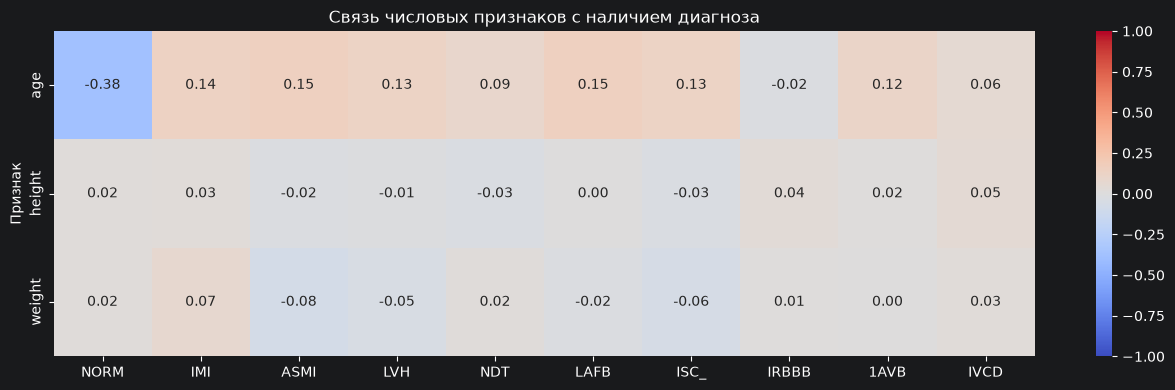

In [29]:
top_labels = (
    target.loc[has_diagnosis]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .index
)

matrix = numeric_links.pivot(
    index='Признак',
    columns='Диагноз',
    values='Корреляция'
).reindex(index=num_cols, columns=top_labels)

plt.figure(figsize=(13, 4))

sns.heatmap(
    matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1
)

plt.title('Связь числовых признаков с наличием диагноза')
plt.tight_layout()
plt.show()

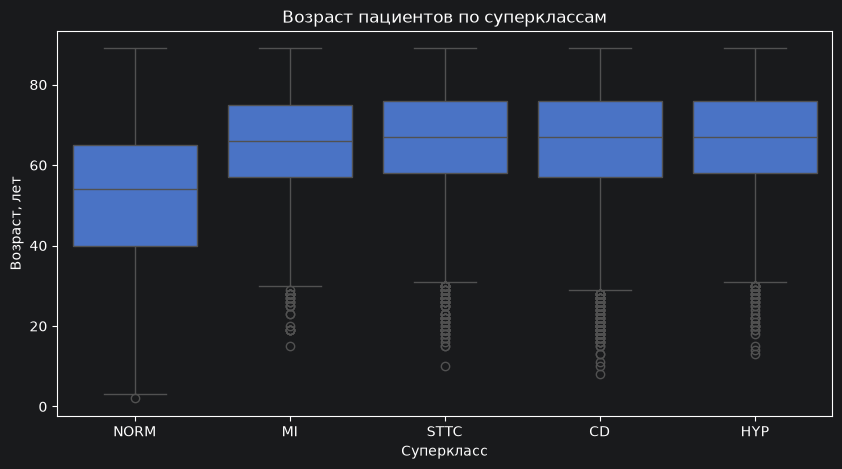

In [57]:
df_age = data.explode("diagnostic_classes", ignore_index=True)
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df_age,
    x="diagnostic_classes",
    y="age",
    order=["NORM", "MI", "STTC", "CD", "HYP"]
)

plt.title("Возраст пациентов по суперклассам")
plt.xlabel("Суперкласс")
plt.ylabel("Возраст, лет")

plt.show()

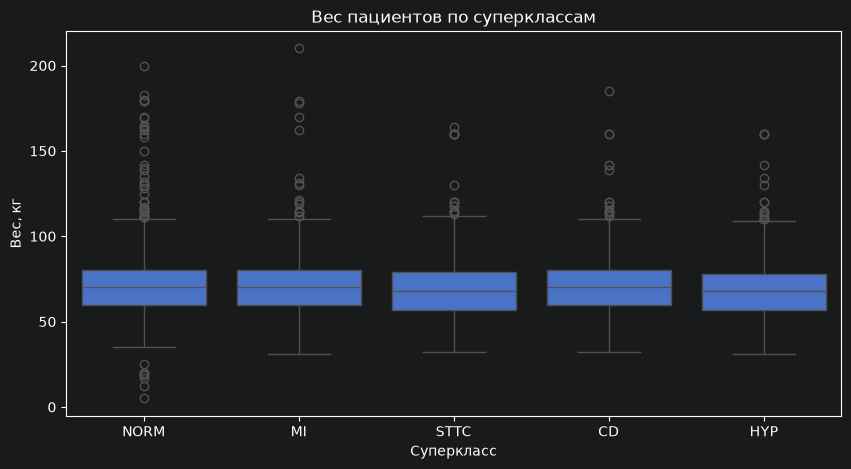

In [58]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df_age,
    x="diagnostic_classes",
    y="weight",
    order=["NORM", "MI", "STTC", "CD", "HYP"]
)

plt.title("Вес пациентов по суперклассам")
plt.xlabel("Суперкласс")
plt.ylabel("Вес, кг")

plt.show()

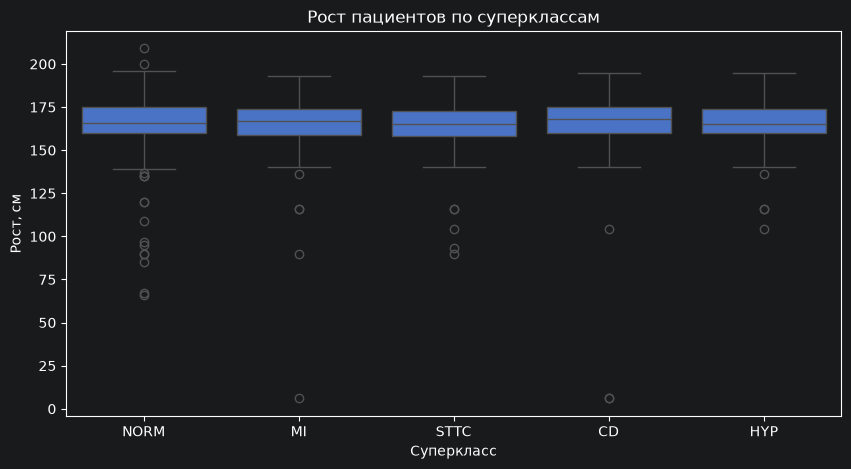

In [59]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df_age,
    x="diagnostic_classes",
    y="height",
    order=["NORM", "MI", "STTC", "CD", "HYP"]
)

plt.title("Рост пациентов по суперклассам")
plt.xlabel("Суперкласс")
plt.ylabel("Рост, см")

plt.show()

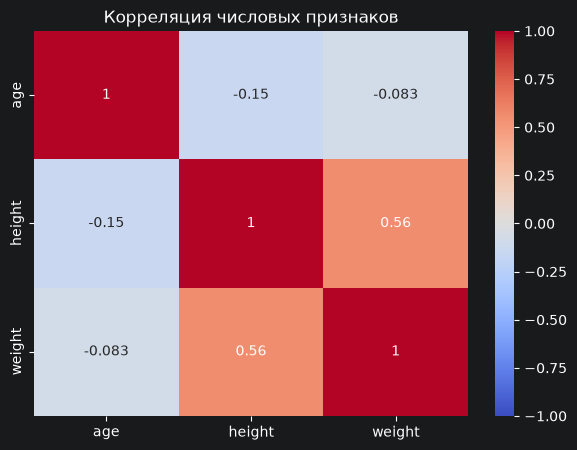

In [31]:
corr = data[["age", "height", "weight"]].corr()

plt.figure(figsize=(7, 5))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Корреляция числовых признаков")
plt.show()

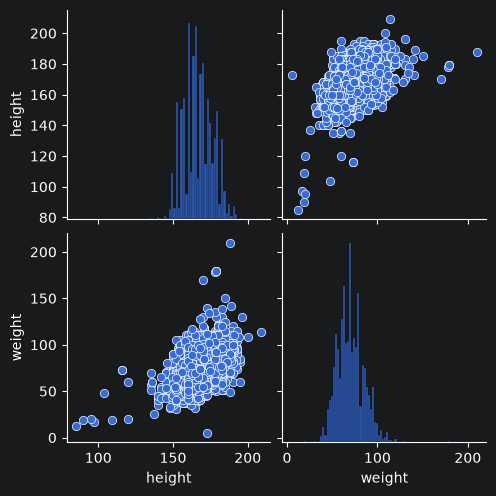

In [32]:
sns.pairplot(
    data[["height", "weight"]].dropna()
)

plt.show()

Сочетаний в анализе: 15
Записей в анализе: 12194
Охват записей с диагнозами: 71.4%


age                      height                       weight  \
            count   mean median    std  count    mean median    std  count   
Диагноз                                                                      
ASMI          333  62.01   62.0  13.48     83  166.46  166.0   9.11     99   
ASMI, IMI     235  66.50   66.0  12.20     45  164.36  163.0  12.01     47   
ASMI, LAFB    132  68.66   69.5  11.46     35  167.14  169.0   9.42     37   
CLBBB         274  66.30   65.0  10.78     68  164.49  164.5   8.92     69   
ILMI          150  60.49   61.0  10.62     21  165.86  165.0   9.96     20   
IMI           794  62.90   62.0  11.64    130  168.38  169.0   9.27    142   
IRBBB         253  55.13   56.0  18.56     73  168.78  168.0  11.25    131   
IRBBB, NORM   195  49.64   53.0  17.48     87  169.56  169.0   9.55    114   
ISCAL         100  66.73   67.5  12.21     28  166.04  165.0   7.47     27   
ISC_, LVH     423  65.54   66.0  12.32    103  165.69  165.0   9.21    103   
LAFB          334  66.47   68.0  12.51    132  167.69  168.0  17.10    155   
LVH           353  61.11   62.0  15.16    180  167.22  166.5  10.11    186   
NDT           972  62.47   63.0  14.36    353  165.89  165.0  10.19    389   
NORM         7214  52.17   54.0  17.38   2456  166.74  166.0  10.81   3863   
NST_          346  65.67   67.0  14.49     98  166.18  165.5   8.75    109   

                                  
              mean median    std  
Диагноз                           
ASMI         67.94   65.0  16.01  
ASMI, IMI    67.79   66.0  13.99  
ASMI, LAFB   70.08   71.0  16.09  
CLBBB        65.41   64.0  12.65  
ILMI         69.40   69.0  18.07  
IMI          82.20   79.5  24.58  
IRBBB        71.24   70.0  16.20  
IRBBB, NORM  70.79   70.0  14.63  
ISCAL        69.96   68.0  13.31  
ISC_, LVH    67.10   64.0  17.44  
LAFB         72.95   70.0  14.94  
LVH          71.46   70.5  14.60  
NDT          72.59   70.0  16.53  
NORM         70.84   70.0  15.42  
NST_         68.48   67.0  14.22

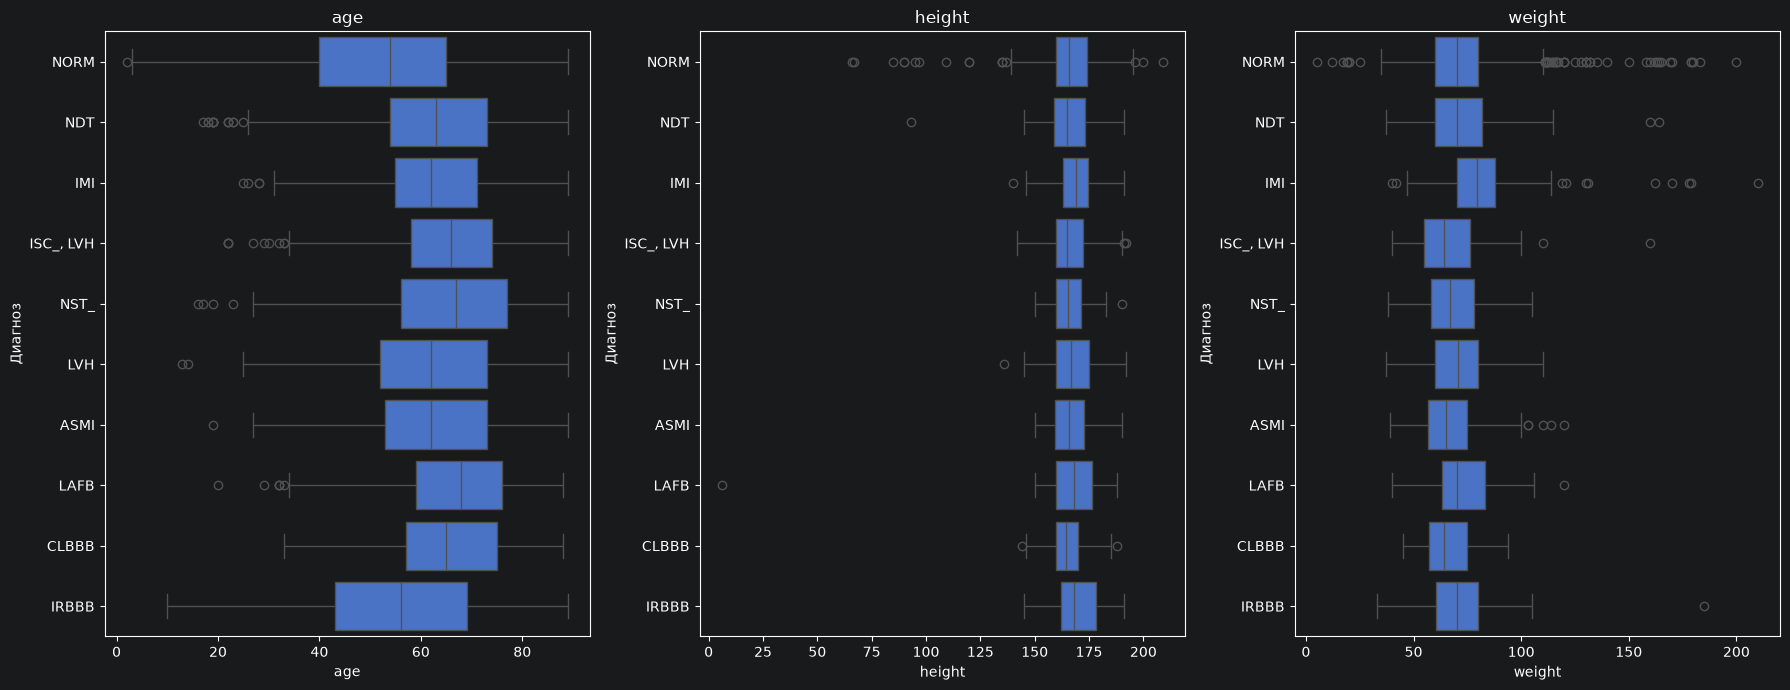

In [51]:
def cramers_v(x, y):
    pair = pd.concat(
        [x.rename('x'), y.rename('y')],
        axis=1
    ).dropna()

    table = pd.crosstab(pair['x'], pair['y'])

    if min(table.shape) < 2:
        return np.nan

    return association(
        table.to_numpy(),
        method='cramer',
        correction=False
    )

min_count = 100

set_counts = label_set[has_diagnosis].value_counts()
frequent_sets = set_counts[set_counts >= min_count].index

selected = has_diagnosis & label_set.isin(frequent_sets)

print('Сочетаний в анализе:', len(frequent_sets))
print('Записей в анализе:', selected.sum())
print(
    'Охват записей с диагнозами:',
    f'{selected.sum() / has_diagnosis.sum():.1%}'
)

# Категориальные признаки и точные сочетания диагнозов
set_links = pd.DataFrame({
    'Признак': cat_cols,
    'V Крамера': [
        cramers_v(
            data.loc[selected, feature],
            label_set[selected]
        )
        for feature in cat_cols
    ]
}).sort_values('V Крамера', ascending=False)
comparison = data.loc[selected, num_cols].copy()
comparison['Диагноз'] = label_set[selected]

summary = comparison.groupby('Диагноз')[num_cols].agg(
    ['count', 'mean', 'median', 'std']
)

display(summary.round(2))

# До 10 наиболее частых сочетаний
order = set_counts.loc[frequent_sets].head(10).index

fig, axes = plt.subplots(1, 3, figsize=(18, 7))

for ax, feature in zip(axes, num_cols):
    sns.boxplot(
        data=comparison[comparison['Диагноз'].isin(order)],
        x=feature,
        y='Диагноз',
        order=order,
        ax=ax
    )

    ax.set_title(feature)

plt.tight_layout()
plt.show()

In [34]:
from itertools import combinations
rows = []

for first, second in combinations(cat_cols, 2):
    valid = data[[first, second]].notna().all(axis=1)

    rows.append({
        'Признак 1': first,
        'Признак 2': second,
        'V Крамера': cramers_v(data[first], data[second]),
        'Записей': int(valid.sum())
    })

category_pairs = pd.DataFrame(rows).sort_values(
    'V Крамера',
    ascending=False
)

display(category_pairs.round(3))


,Признак 1,Признак 2,V Крамера,Записей
32,device,initial_autogenerated_report,0.976,17084
33,device,validated_by_human,0.964,17084
54,initial_autogenerated_report,validated_by_human,0.915,17084
18,nurse,validated_by_human,0.793,16062
10,nurse,site,0.769,16051
26,site,validated_by_human,0.760,17070
40,infarction_stadium1,infarction_stadium2,0.742,83
17,nurse,initial_autogenerated_report,0.723,16062
25,site,initial_autogenerated_report,0.695,17070
23,site,validated_by,0.589,9126


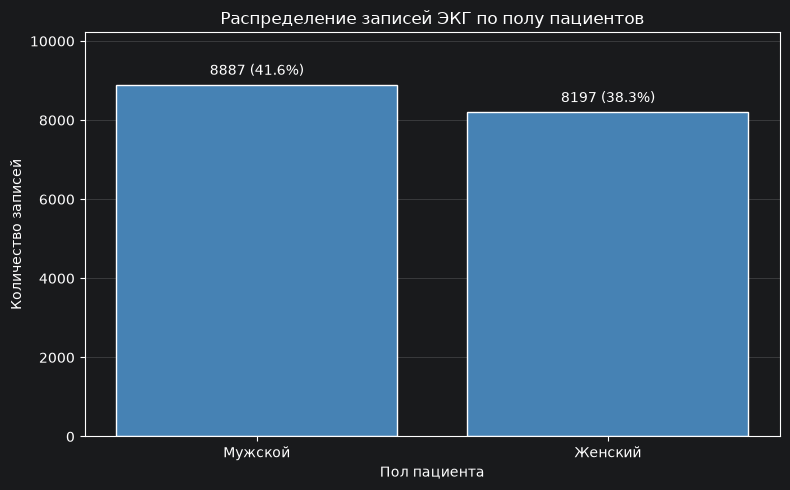

In [35]:
sex = data['sex'].map({0: 'Мужской', 1: 'Женский'})
sex = sex.fillna('Неизвестный код')
sex = sex.mask(data['sex'].isna(), 'Не указан')

counts = sex.value_counts().reindex(
    ['Мужской', 'Женский', 'Не указан', 'Неизвестный код'],
    fill_value=0
)

# Убираем отсутствующие категории
counts = counts[counts > 0]

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    counts.index,
    counts.values,
    color='steelblue',
    edgecolor='white'
)

labels = [
    f'{n} ({n / len(ptbxl_database):.1%})'
    for n in counts
]

ax.bar_label(bars, labels=labels, padding=5)

ax.set(
    title='Распределение записей ЭКГ по полу пациентов',
    xlabel='Пол пациента',
    ylabel='Количество записей'
)

ax.margins(y=0.15)
ax.grid(axis='y', alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

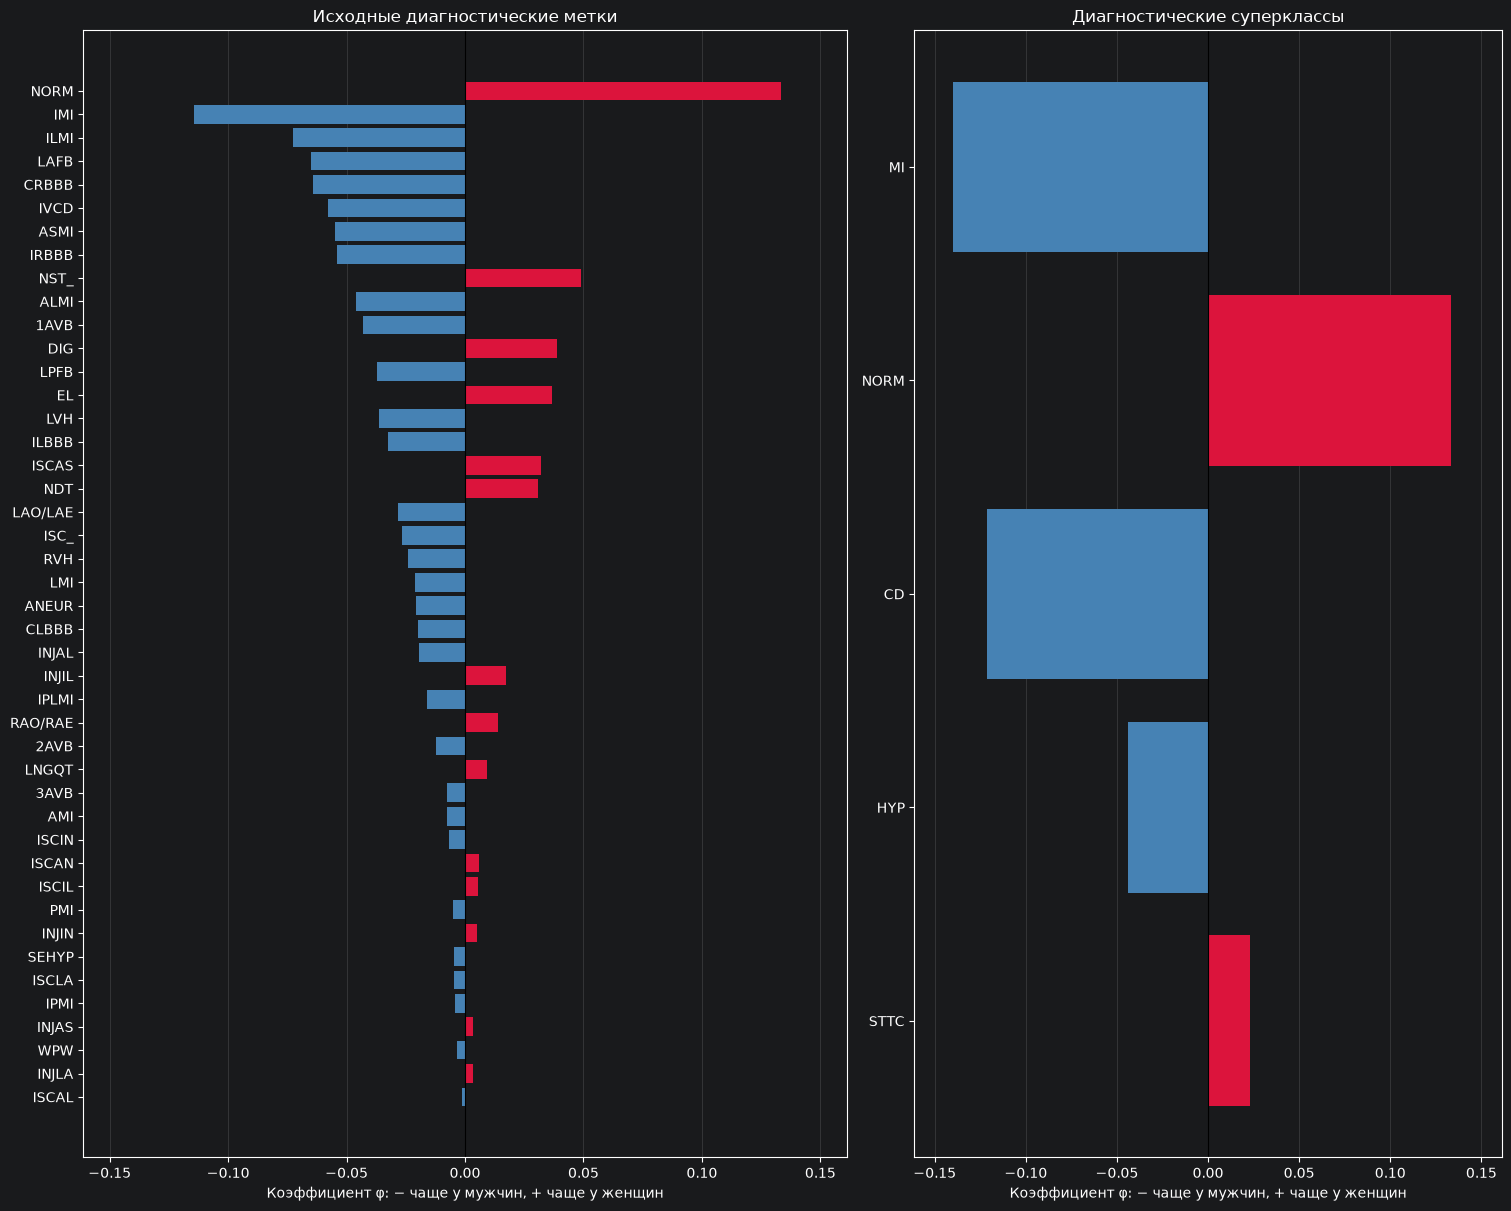

Пол и диагностические суперклассы:


,Метка,φ,Записей мужчин,Записей женщин,С меткой: мужчины,С меткой: женщины,"Доля у мужчин, %","Доля у женщин, %","Разница Ж−М, п.п."
0,MI,-0.140,8887,8197,2800,1579,31.507,19.263,-12.244
1,NORM,0.134,8887,8197,3385,4211,38.089,51.372,13.283
2,CD,-0.122,8887,8197,2468,1439,27.771,17.555,-10.216
3,HYP,-0.044,8887,8197,1226,893,13.795,10.894,-2.901
4,STTC,0.023,8887,8197,2093,2093,23.551,25.534,1.982


In [36]:
def parse_codes(value):
    if isinstance(value, dict):
        return value
    if isinstance(value, str):
        parsed = ast.literal_eval(value)
        if isinstance(parsed, dict):
            return parsed
    raise ValueError(f"Некорректное значение scp_codes: {value!r}")

codes = data['scp_codes'].apply(parse_codes)

# Предполагается, что коды SCP находятся в индексе scp
diagnostic_ref = scp.loc[scp['diagnostic'].eq(1)].copy()
diagnostic_codes = set(diagnostic_ref.index)

# Исключаем записи без диагностической разметки
has_diagnostic = codes.apply(
    lambda value: bool(set(value) & diagnostic_codes)
)

data = data.loc[has_diagnostic].reset_index(drop=True)
codes = codes.loc[has_diagnostic].reset_index(drop=True)

# Матрица 44 исходных диагностических меток
y_diagnostic = pd.DataFrame({
    code: codes.apply(lambda value: int(code in value))
    for code in sorted(diagnostic_codes)
})

sex = pd.to_numeric(data['sex'], errors='coerce')

# Оставляем только корректные значения пола
sex = sex.where(sex.isin([0, 1]))

def sex_label_associations(sex, target):
    # Проверка соответствия строк признака и меток
    assert sex.index.equals(target.index), "Индексы таблиц не совпадают"

    rows = []

    for label in target.columns:
        pair = pd.DataFrame({
            'sex': sex,
            'label': target[label]
        }).dropna()

        men = pair.loc[pair['sex'].eq(0), 'label']
        women = pair.loc[pair['sex'].eq(1), 'label']

        men_share = men.mean()
        women_share = women.mean()

        phi = (
            pair['sex'].corr(pair['label'])
            if pair['sex'].nunique() == 2
            and pair['label'].nunique() == 2
            else np.nan
        )

        rows.append({
            'Метка': label,
            'φ': phi,
            'Записей мужчин': len(men),
            'Записей женщин': len(women),
            'С меткой: мужчины': int(men.sum()),
            'С меткой: женщины': int(women.sum()),
            'Доля у мужчин, %': men_share * 100,
            'Доля у женщин, %': women_share * 100,
            'Разница Ж−М, п.п.': (women_share - men_share) * 100
        })

    return (
        pd.DataFrame(rows)
        .assign(abs_phi=lambda table: table['φ'].abs())
        .sort_values('abs_phi', ascending=False)
        .drop(columns='abs_phi')
        .reset_index(drop=True)
    )
superclass_names = ['NORM', 'MI', 'STTC', 'CD', 'HYP']

y_superclass = pd.DataFrame({
    superclass: y_diagnostic.loc[
        :,
        diagnostic_ref.index[
            diagnostic_ref['diagnostic_class'].eq(superclass)
        ]
    ].any(axis=1).astype(int)
    for superclass in superclass_names
})
sex_diagnostic = sex_label_associations(sex, y_diagnostic)
sex_superclass = sex_label_associations(sex, y_superclass)

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 12),
    gridspec_kw={'width_ratios': [1.3, 1]},
    constrained_layout=True
)

for ax, table, title in [
    (axes[0], sex_diagnostic, 'Исходные диагностические метки'),
    (axes[1], sex_superclass, 'Диагностические суперклассы')
]:
    plot_data = table.dropna(subset=['φ'])

    colors = [
        'crimson' if value > 0 else 'steelblue'
        for value in plot_data['φ']
    ]

    ax.barh(plot_data['Метка'], plot_data['φ'], color=colors)
    ax.invert_yaxis()
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_title(title)
    ax.set_xlabel('Коэффициент φ: − чаще у мужчин, + чаще у женщин')
    ax.grid(axis='x', alpha=0.25)
    ax.set_axisbelow(True)

# Одинаковый масштаб для сравнения двух графиков
max_abs = pd.concat([
    sex_diagnostic['φ'],
    sex_superclass['φ']
]).abs().max()

limit = max(0.05, max_abs * 1.15) if pd.notna(max_abs) else 0.05

for ax in axes:
    ax.set_xlim(-limit, limit)

fig.savefig(
    'sex_diagnosis_correlations.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()
print('Пол и диагностические суперклассы:')
display(sex_superclass.round(3))

Анализ показал, что рост и вес пациентов умеренно связаны между собой (r = 0,55): более высокие пациенты обычно имеют больший вес. При этом возраст имеет слабую линейную связь с ростом и весом.
Также выяснилось, что пациенты класса NORM в среднем моложе: их медианный возраст составляет около 55 лет, а у пациентов классов MI, STTC, CD и HYP около 65 лет.
Таким образом, из рассмотренных метаданных наиболее заметная связь с диагностическими суперклассами наблюдается у признака age.
Также, в среднем присутствует слабая корреляция между диагностическими суперклассами и полом пациента.


Корреляционный анализ показал, что большинство рассмотренных метаданных имеют слабую линейную связь с диагностическими суперклассами. Наиболее заметная связь наблюдается у возраста. Однако низкая корреляция не означает, что остальные признаки не могут быть полезны для модели.
Поэтому на первом этапе планируется обучить модель только на 12 отведениях ЭКГ. Затем будет проведён отдельный этап работ с добавлением возраста и пола пациента или других метаданных. Результаты моделей будут сравниваться на одной валидационной выборке, чтобы проверить, помогают ли дополнительные данные улучшить качество классификации.
Рост, вес и ИМТ на первоначальном этапе использовать не планируется из-за большого количества пропусков. Их возможную пользу можно исследовать в дальнейшем.

## Выводы

В ходе разведочного анализа PTB-XL были изучены диагностические суперклассы, метаданные пациентов и сигналы ЭКГ. Анализ показал, что классы распределены неравномерно, а одна запись может относиться сразу к нескольким суперклассам. Также, присутствуют записи без суперклассов, они были удалены из выборки.
Также было выявлено, что большая часть записей получена из одной клиники, что может влиять на разнообразие данных. В метаданных обнаружено много пропущенных значений, особенно в информации о росте и весе пациентов. Корреляционный анализ показал, что большинство рассмотренных характеристик слабо связаны с диагностическими суперклассами, а наиболее заметная связь наблюдается у возраста.
Кроме того, часть записей содержит отметки о помехах, поэтому качество сигналов также необходимо учитывать.